In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.shape

(2443651, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [6]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

1-Frequency Tables:

Generate a frequency table for the product category.
Which are the top 5 most listed product categories?

In [7]:
freqency_table = df['category'].value_counts()
proportion_table = df['category'].value_counts(normalize=True)
freqency_table,proportion_table

(category
 Sports & Outdoors                         836265
 Beauty                                     19312
 Handmade Clothing, Shoes & Accessories     19229
 Bath & Body                                19092
 Birthday Gifts                             18978
                                            ...  
 Alexa Built-In Devices                       107
 Motorbike Chassis                            107
 Plugs                                        107
 Smart Home Security & Lighting               104
 Smart Speakers                                54
 Name: count, Length: 296, dtype: int64,
 category
 Sports & Outdoors                         0.342219
 Beauty                                    0.007903
 Handmade Clothing, Shoes & Accessories    0.007869
 Bath & Body                               0.007813
 Birthday Gifts                            0.007766
                                             ...   
 Alexa Built-In Devices                    0.000044
 Motorbike Chassis       

In [8]:
df_categorical = df.select_dtypes("object")
df_categorical

,asin,title,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,Hi-Fi Speakers
...,...,...,...
2443646,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",Motorbike Clothing
2443647,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,Motorbike Clothing
2443648,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,Motorbike Clothing
2443649,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,Motorbike Clothing


In [9]:
my_table = pd.crosstab(index = df_categorical["category"], 
                              columns="count")      
my_table

col_0,count
category,
3D Printers,248
3D Printing & Scanning,4067
Abrasive & Finishing Products,250
Action Cameras,1697
Adapters,254
...,...
Wind Instruments,250
Window Treatments,239
Women,17772


C:\Users\pariy\AppData\Local\Temp\ipykernel_28292\724539565.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10.index, y=top_10["count"], palette="Set3",legend=False);


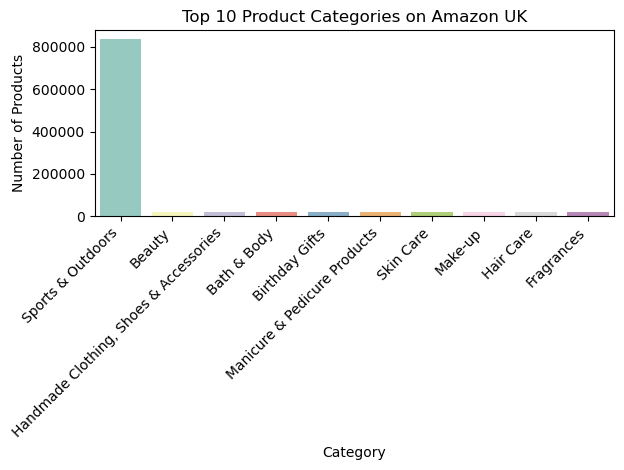

In [10]:
top_10 = my_table.sort_values(by="count",ascending= False).head(10)

plt.Figure(figsize=(12,6))
sns.barplot(x=top_10.index, y=top_10["count"], palette="Set3",legend=False);
plt.xticks(rotation=45, ha="right")

plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

Part 2: Delving into Product Pricing

In [12]:
df['price'].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [13]:
df['price'].mode()

0    9.99
Name: price, dtype: float64

#What's the average price point of products listed? How does this compare with the most common price point (mode)?

The average price (mean) is about 8.9 , while the most common price (mode) is 9.99.
The median is 1.90.

The mean is much higher than the mode and the median. This means a small number
of very expensive products pull the average up. So the mean does not represent
a "typical" product price well. Most products are priced closer to the mode/median

In [14]:
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price

(119445.48532256528,
 345.60886175352226,
 0.0,
 100000.0,
 100000.0,
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

In [15]:
skewness_price = df['price'].skew()
kurtosis_price = df['price'].kurtosis()

skewness_price, kurtosis_price

(np.float64(27.49297756628037), np.float64(4241.616412866521))

<Axes: xlabel='price', ylabel='Count'>

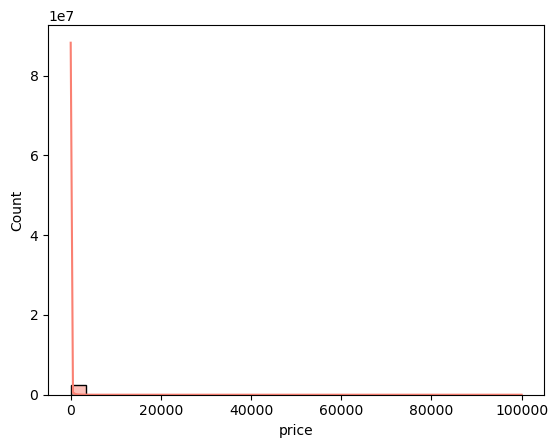

In [16]:
sns.histplot(df['price'], kde=True, bins=30, color="salmon")

Upper bound: 99.99000000000001


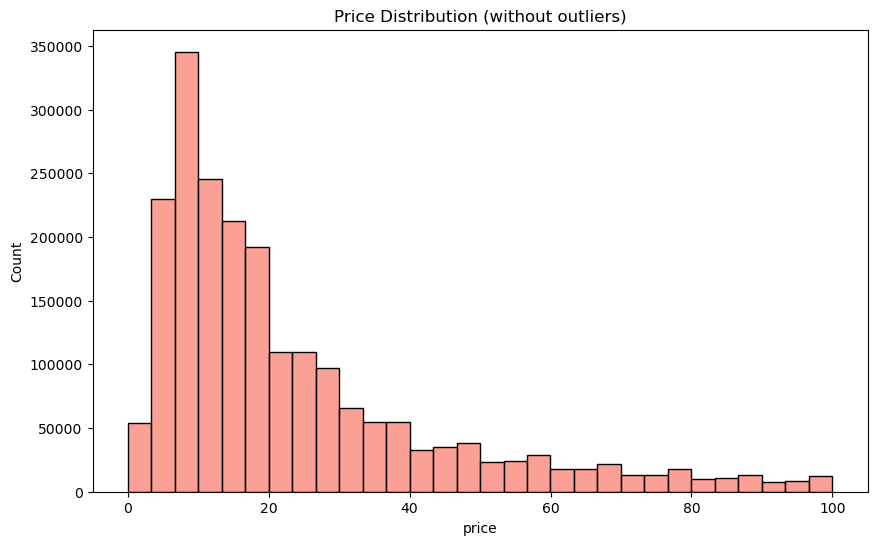

In [17]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
print("Upper bound:", upper_bound)

df_no_outliers = df[df['price'] <= upper_bound]

plt.figure(figsize=(10, 6))
sns.histplot(df_no_outliers['price'], bins=30, color="salmon")
plt.title("Price Distribution (without outliers)")
plt.show()

most products are priced between about £5 and £20,
with a peak around £7–£10 (matching the mode of £9.99).
The distribution is right-skewed: many cheap products and a long tail of
more expensive ones.

<Axes: ylabel='price'>

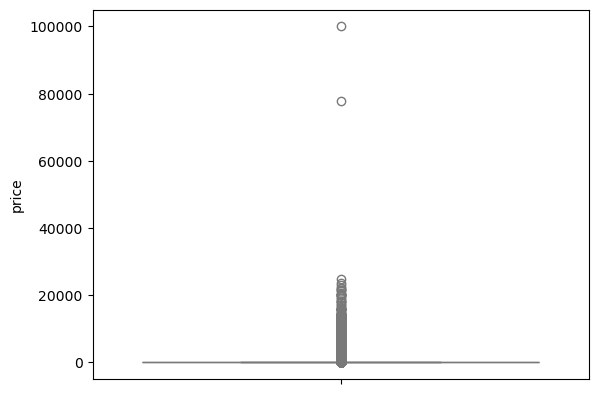

In [18]:
sns.boxplot(data = df['price'], color="lightblue")

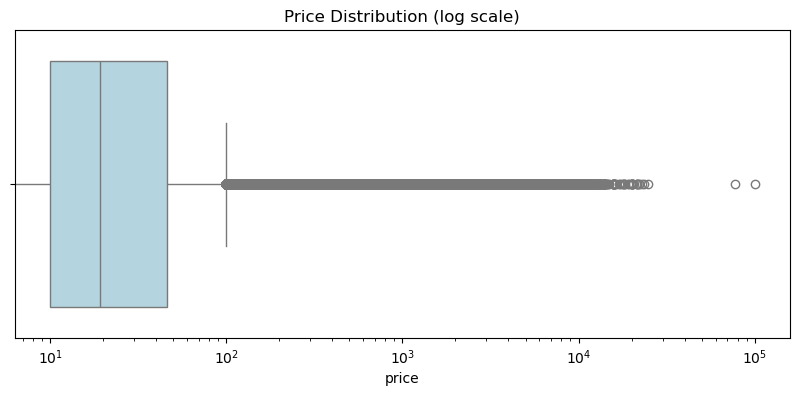

In [19]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price'], color="lightblue")
plt.xscale("log")
plt.title("Price Distribution (log scale)")
plt.show()

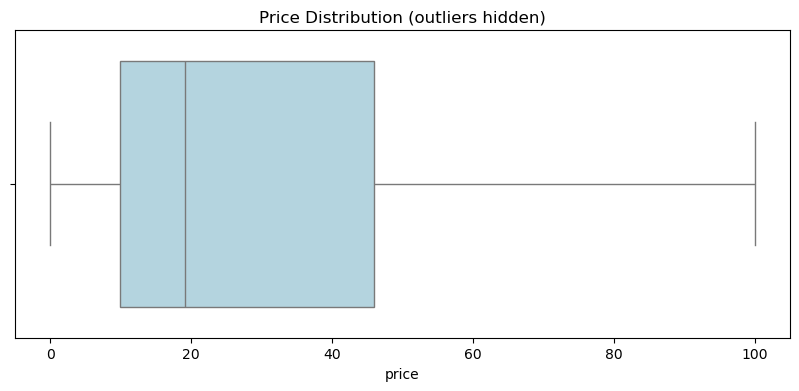

In [20]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price'], color="lightblue", showfliers=False)
plt.title("Price Distribution (outliers hidden)")
plt.show()

The box plot confirms many high-priced outliers. The box itself (middle 50% of
products) is so small that it is almost invisible near zero, while many products
are priced far above the upper bound (~£100), reaching up to about £25,000,
with a few extreme cases near £78,000 and £100,000.

##Part 3: Unpacking Product Rating

In [21]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [26]:
mean_rating = df['stars'].mean()
mean_rating


np.float64(2.152836472966066)

In [25]:
median_rating = df['stars'].median()
median_rating

0.0

In [24]:
mode_rating = df['stars'].mode()
mode_rating

0    0.0
Name: stars, dtype: float64

In [28]:
df[df['stars'] == 0]['reviews'].max()

0

All products with a rating of 0 have 0 reviews. So a rating of 0 does not mean
"bad rating" — it means "not rated yet". These values were excluded from the
rating analysis to avoid misleading results.

In [30]:
rated = df[df['stars'] > 0]

In [31]:
variance_rating = rated['stars'].var()
std_rating = rated['stars'].std()
iqr_rating = rated['stars'].quantile(0.75) - rated['stars'].quantile(0.25)

variance_rating, std_rating, iqr_rating

(0.3083433752380519, 0.5552867504614637, np.float64(0.5))

In [32]:
skewness_rating = rated['stars'].skew()
kurtosis_rating = rated['stars'].kurtosis()

skewness_rating, kurtosis_rating

(np.float64(-2.379568112212799), np.float64(9.78193769066435))

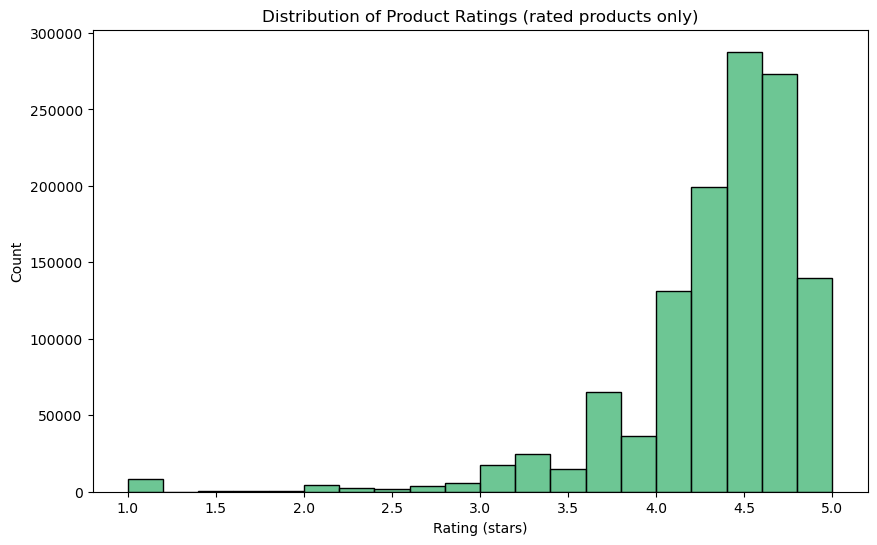

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(rated['stars'], bins=20, color="mediumseagreen")
plt.title("Distribution of Product Ratings (rated products only)")
plt.xlabel("Rating (stars)")
plt.show()

The ratings are left-skewed (negative skewness): most products receive high
ratings, and only a small number receive low ratings. This means customers
on Amazon UK are generally satisfied, and ratings are not normally distributed.